# 01 - Exploratory Data Analysis: Sri Lanka Weather Dataset

**Activity:** MSc Applied Machine Learning class activity (Random Forest vs XGBoost ensembles).
**Dataset:** *Sri Lanka Weather Dataset* by rasulmah on Kaggle (CC0). Daily weather for 30 Sri Lankan cities, taken from the Open-Meteo historical weather service.
**Goal of this notebook:** understand the data before modelling, and decide the prediction target.

Run this notebook from the `notebooks/` folder. It reads only `data/raw/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW_FILE = Path("../data/raw/SriLanka_Weather_Dataset.csv")
RAIN_THRESHOLD_MM = 1.0        # a "rainy day" has at least 1 mm of rain (standard wet-day threshold)

# One look for all charts
BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#898781", "#0b0b0b"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 12,
    "legend.frameon": False, "lines.linewidth": 2, "figure.dpi": 110,
})
pd.set_option("display.max_columns", 40)

## 1. Load the data and look at its structure

In [2]:
df = pd.read_csv(RAW_FILE)
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (147480, 24)


,time,weathercode,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,apparent_temperature_min,apparent_temperature_mean,sunrise,sunset,shortwave_radiation_sum,precipitation_sum,rain_sum,snowfall_sum,precipitation_hours,windspeed_10m_max,windgusts_10m_max,winddirection_10m_dominant,et0_fao_evapotranspiration,latitude,longitude,elevation,country,city
0,2010-01-01,2,30.0,22.7,26.1,34.4,25.2,29.2,2010-01-01T00:52,2010-01-01T12:35,20.92,0.0,0.0,0.0,0.0,11.7,27.4,20,4.58,7.0,79.899994,16.0,Sri Lanka,Colombo
1,2010-01-02,51,29.9,23.5,26.2,33.8,26.2,29.8,2010-01-02T00:52,2010-01-02T12:36,17.71,0.1,0.1,0.0,1.0,13.0,27.0,24,3.84,7.0,79.899994,16.0,Sri Lanka,Colombo
2,2010-01-03,51,29.5,23.2,26.0,34.3,26.3,29.9,2010-01-03T00:53,2010-01-03T12:36,17.76,0.6,0.6,0.0,3.0,12.3,27.4,16,3.65,7.0,79.899994,16.0,Sri Lanka,Colombo
3,2010-01-04,2,28.9,21.9,25.3,31.6,23.4,27.8,2010-01-04T00:53,2010-01-04T12:37,16.50,0.0,0.0,0.0,0.0,17.0,34.6,356,3.79,7.0,79.899994,16.0,Sri Lanka,Colombo
4,2010-01-05,1,28.1,21.3,24.5,30.1,23.1,26.1,2010-01-05T00:53,2010-01-05T12:37,23.61,0.0,0.0,0.0,0.0,18.7,37.1,355,4.97,7.0,79.899994,16.0,Sri Lanka,Colombo


In [3]:
print(df.dtypes.to_string())

time                              str
weathercode                     int64
temperature_2m_max            float64
temperature_2m_min            float64
temperature_2m_mean           float64
apparent_temperature_max      float64
apparent_temperature_min      float64
apparent_temperature_mean     float64
sunrise                           str
sunset                            str
shortwave_radiation_sum       float64
precipitation_sum             float64
rain_sum                      float64
snowfall_sum                  float64
precipitation_hours           float64
windspeed_10m_max             float64
windgusts_10m_max             float64
winddirection_10m_dominant      int64
et0_fao_evapotranspiration    float64
latitude                      float64
longitude                     float64
elevation                     float64
country                           str
city                              str


In [4]:
print("Missing values per column:")
print(df.isna().sum().to_string())
print("\nTotal missing values:", int(df.isna().sum().sum()))
print("Exact duplicate rows  :", int(df.duplicated().sum()))
print("Duplicate (city, time):", int(df.duplicated(["city", "time"]).sum()))

Missing values per column:
time                          0
weathercode                   0
temperature_2m_max            0
temperature_2m_min            0
temperature_2m_mean           0
apparent_temperature_max      0
apparent_temperature_min      0
apparent_temperature_mean     0
sunrise                       0
sunset                        0
shortwave_radiation_sum       0
precipitation_sum             0
rain_sum                      0
snowfall_sum                  0
precipitation_hours           0
windspeed_10m_max             0
windgusts_10m_max             0
winddirection_10m_dominant    0
et0_fao_evapotranspiration    0
latitude                      0
longitude                     0
elevation                     0
country                       0
city                          0

Total missing values: 0


Exact duplicate rows  : 0
Duplicate (city, time): 0


In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
weathercode,147480.0,46.65,21.62,0.00,51.00,53.00,61.00,65.00
temperature_2m_max,147480.0,29.24,2.12,17.50,28.20,29.20,30.40,37.50
temperature_2m_min,147480.0,23.90,2.06,12.10,23.10,24.30,25.20,30.00
temperature_2m_mean,147480.0,26.23,1.84,16.30,25.60,26.40,27.20,31.80
apparent_temperature_max,147480.0,34.11,2.97,18.50,32.40,34.20,36.10,43.40
apparent_temperature_min,147480.0,27.71,2.84,10.50,26.40,28.40,29.60,34.70
apparent_temperature_mean,147480.0,30.32,2.54,16.30,29.20,30.80,31.90,37.40
shortwave_radiation_sum,147480.0,18.48,4.21,1.23,16.22,19.13,21.51,28.98
precipitation_sum,147480.0,5.98,10.22,0.00,0.40,2.60,7.50,338.80
rain_sum,147480.0,5.98,10.22,0.00,0.40,2.60,7.50,338.80


## 2. Time column, granularity and field types

In [6]:
df["time"] = pd.to_datetime(df["time"])
print("Time column : time")
print("Date range  :", df["time"].min().date(), "to", df["time"].max().date())
print("Cities      :", df["city"].nunique())
print("Rows per city:", df.groupby("city").size().unique(), "-> one row per city per day (daily data)")
print("\nCategorical fields:", ["city", "country", "weathercode"])
print("Numeric fields    :", [c for c in df.select_dtypes("number").columns if c != "weathercode"])
print("\nCities:", ", ".join(sorted(df["city"].unique())))

Time column : time
Date range  : 2010-01-01 to 2023-06-17
Cities      : 30
Rows per city: [4916] -> one row per city per day (daily data)

Categorical fields: ['city', 'country', 'weathercode']
Numeric fields    : ['temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'apparent_temperature_max', 'apparent_temperature_min', 'apparent_temperature_mean', 'shortwave_radiation_sum', 'precipitation_sum', 'rain_sum', 'snowfall_sum', 'precipitation_hours', 'windspeed_10m_max', 'windgusts_10m_max', 'winddirection_10m_dominant', 'et0_fao_evapotranspiration', 'latitude', 'longitude', 'elevation']

Cities: Athurugiriya, Badulla, Bentota, Colombo, Galle, Gampaha, Hambantota, Hatton, Jaffna, Kalmunai, Kalutara, Kandy, Kesbewa, Kolonnawa, Kurunegala, Mabole, Maharagama, Mannar, Matale, Matara, Moratuwa, Mount Lavinia, Negombo, Oruwala, Pothuhera, Puttalam, Ratnapura, Sri Jayewardenepura Kotte, Trincomalee, Weligama


In [7]:
# Columns that carry no information
print("country values           :", list(df["country"].unique()))
print("snowfall_sum non-zero rows:", int((df["snowfall_sum"] != 0).sum()))
print("precipitation_sum equals rain_sum in every row:", bool((df["precipitation_sum"] == df["rain_sum"]).all()))

country values           : ['Sri Lanka']
snowfall_sum non-zero rows: 0
precipitation_sum equals rain_sum in every row: True


**Findings so far**

- 147,480 rows and 24 columns: 30 cities x 4,916 days (1 January 2010 to 17 June 2023). The data is **daily, per city**.
- There are **no missing values and no duplicate rows**, so no value has to be imputed in the raw data. (The model pipeline still contains imputers, so a blank value in new data cannot break it.)
- Three columns are useless and will be dropped: `country` (always "Sri Lanka"), `snowfall_sum` (always 0) and `precipitation_sum` (identical to `rain_sum`).

## 3. Rainfall over time

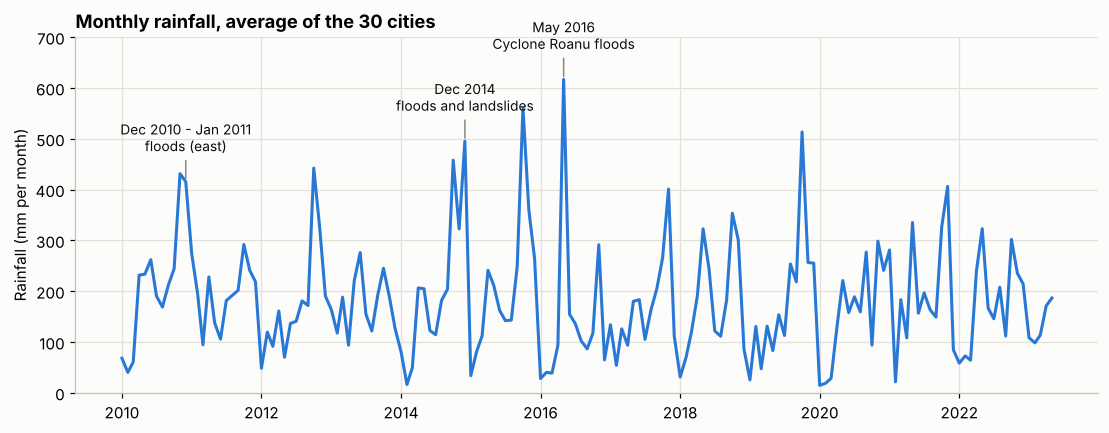

In [8]:
# Monthly rain total of each city, then the average over the 30 cities
monthly = (df.groupby([pd.Grouper(key="time", freq="MS"), "city"])["rain_sum"].sum()
             .groupby("time").mean())
monthly = monthly.iloc[:-1]            # June 2023 is not a full month

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(monthly.index, monthly.values, color=BLUE)
ax.set_ylabel("Rainfall (mm per month)")
ax.set_title("Monthly rainfall, average of the 30 cities")
ax.set_ylim(0, 700)

# Well-known Sri Lankan flood events that are visible in the data
events = {"2010-12-01": "Dec 2010 - Jan 2011\nfloods (east)",
          "2014-12-01": "Dec 2014\nfloods and landslides",
          "2016-05-01": "May 2016\nCyclone Roanu floods"}
for date, label in events.items():
    x = pd.Timestamp(date)
    ax.annotate(label, xy=(x, monthly[x]), xytext=(x, monthly[x] + 60), ha="center", fontsize=9,
                color=INK, arrowprops=dict(arrowstyle="-", color=GREY))
plt.show()

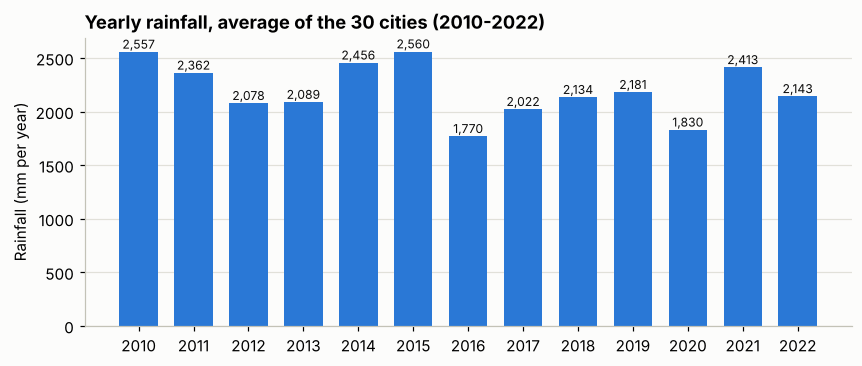

In [9]:
yearly = df[df["time"].dt.year < 2023].groupby([df["time"].dt.year, "city"])["rain_sum"].sum().groupby("time").mean()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(yearly.index, yearly.values, color=BLUE, width=0.7)
for x, v in zip(yearly.index, yearly.values):
    ax.text(x, v + 30, f"{v:,.0f}", ha="center", fontsize=8, color=INK)
ax.set_xticks(yearly.index); ax.set_ylabel("Rainfall (mm per year)")
ax.set_title("Yearly rainfall, average of the 30 cities (2010-2022)"); ax.grid(axis="x", visible=False)
plt.show()

The series has **no long-term upward or downward trend**, but a strong pattern that repeats every year (the monsoons) with some extreme months on top. The three largest spikes match well-known flood events: the December 2010 to January 2011 floods, the December 2014 floods and landslides, and the May 2016 floods linked to Cyclone Roanu.

## 4. Seasonality: when and where does it rain?

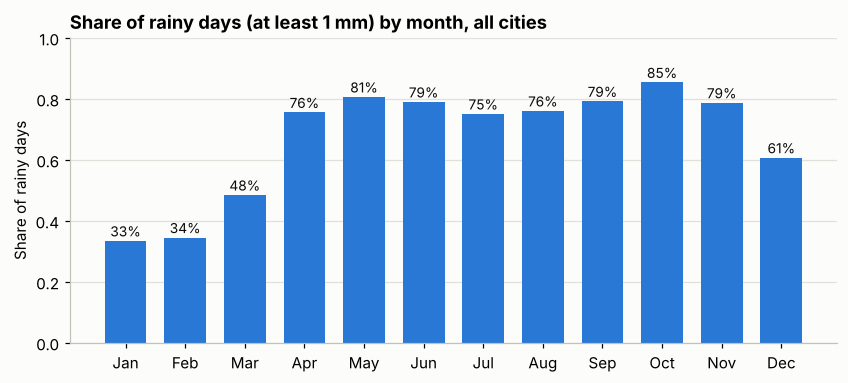

In [10]:
df["rainy"] = df["rain_sum"] >= RAIN_THRESHOLD_MM
df["month"] = df["time"].dt.month
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

by_month = df.groupby("month")["rainy"].mean()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(month_names, by_month.values, color=BLUE, width=0.7)
for i, v in enumerate(by_month.values):
    ax.text(i, v + 0.015, f"{v:.0%}", ha="center", fontsize=9, color=INK)
ax.set_ylim(0, 1); ax.set_ylabel("Share of rainy days"); ax.grid(axis="x", visible=False)
ax.set_title("Share of rainy days (at least 1 mm) by month, all cities")
plt.show()

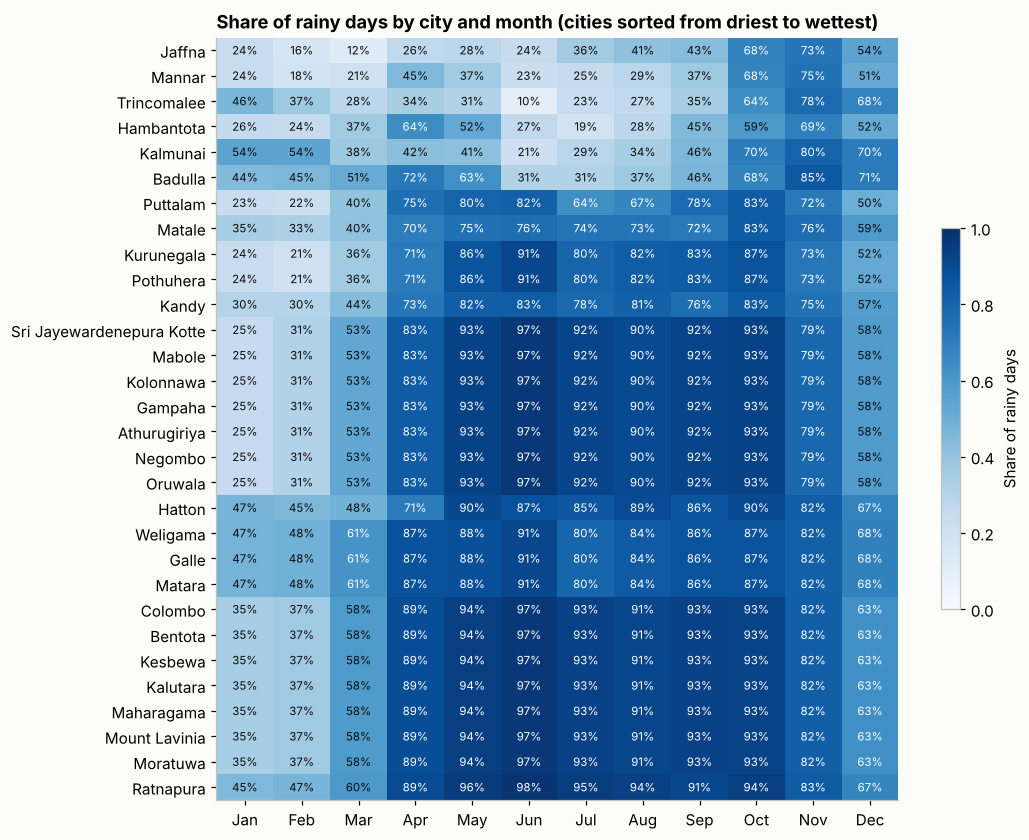

In [11]:
# City x month: the two monsoons hit different parts of the island
heat = df.pivot_table(index="city", columns="month", values="rainy", aggfunc="mean")
heat = heat.loc[heat.mean(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(heat.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(12), month_names); ax.set_yticks(range(len(heat)), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7.5, color="white" if v > 0.6 else INK)
ax.grid(False); ax.set_title("Share of rainy days by city and month (cities sorted from driest to wettest)")
fig.colorbar(im, ax=ax, shrink=0.5, label="Share of rainy days")
plt.show()

This matches Sri Lanka's climate seasons:

| Season | Months | What the data shows |
|---|---|---|
| First inter-monsoon | March - April | Rain starts to increase everywhere |
| Southwest monsoon | May - September | Very wet in the south-west (Colombo, Galle, Ratnapura); **dry** in Jaffna, Mannar, Trincomalee and Hambantota |
| Second inter-monsoon | October - November | Wettest period for the whole island |
| Northeast monsoon | December - February | The east coast (Trincomalee, Kalmunai) still gets rain; the driest season for the rest of the island |

So the same month means different things in different cities. The model needs **both the season and the city** as features.

## 5. How much does today tell us about tomorrow?

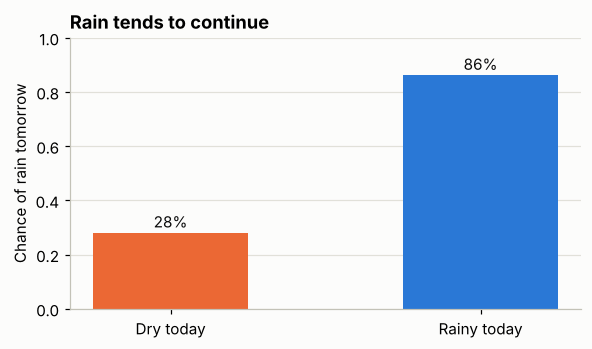

Overall share of rainy days: 67.0%


In [12]:
d = df.sort_values(["city", "time"]).copy()
d["rain_tomorrow"] = d.groupby("city")["rainy"].shift(-1)
d = d.dropna(subset=["rain_tomorrow"])
persistence = d.groupby("rainy")["rain_tomorrow"].mean()

fig, ax = plt.subplots(figsize=(6, 3.2))
labels = ["Dry today", "Rainy today"]
ax.bar(labels, [persistence[False], persistence[True]], color=[ORANGE, BLUE], width=0.5)
for i, v in enumerate([persistence[False], persistence[True]]):
    ax.text(i, v + 0.02, f"{v:.0%}", ha="center", color=INK)
ax.set_ylim(0, 1); ax.set_ylabel("Chance of rain tomorrow"); ax.grid(axis="x", visible=False)
ax.set_title("Rain tends to continue")
plt.show()
print(f"Overall share of rainy days: {df['rainy'].mean():.1%}")

After a rainy day, the next day is rainy 86% of the time. After a dry day, only 28%. Weather comes in spells, so **rain today and rain in the last few days** will be the strongest features. It also means a very simple rule ("tomorrow = today") is a strong baseline that the models must beat.

## 6. Skewed features and the log transform

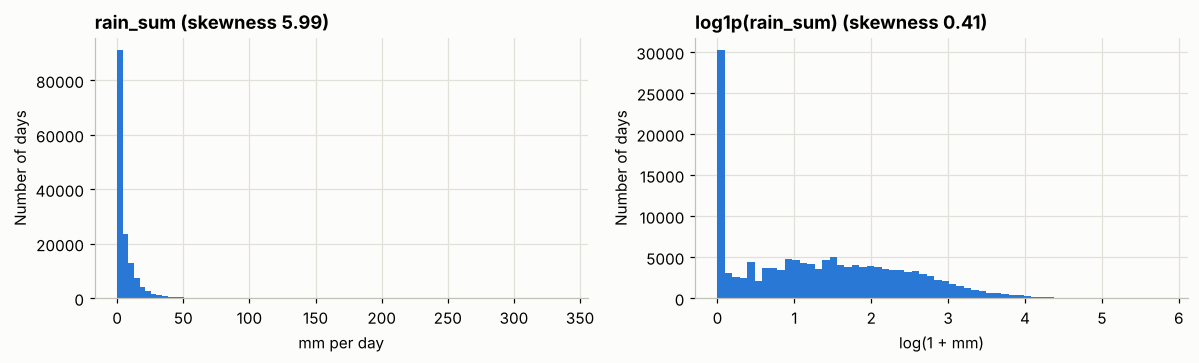

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(df["rain_sum"], bins=80, color=BLUE)
axes[0].set_title(f"rain_sum (skewness {df['rain_sum'].skew():.2f})"); axes[0].set_xlabel("mm per day")
axes[1].hist(np.log1p(df["rain_sum"]), bins=60, color=BLUE)
axes[1].set_title(f"log1p(rain_sum) (skewness {np.log1p(df['rain_sum']).skew():.2f})"); axes[1].set_xlabel("log(1 + mm)")
for ax in axes: ax.set_ylabel("Number of days")
plt.tight_layout(); plt.show()

Daily rain is strongly right-skewed: most days have little rain and a few days have more than 100 mm. `log1p` (log of 1 + value, which is safe for zeros) brings the skewness from about 6 down to about 0.4. This transform is applied to all rain-amount features in the model pipeline.

## 7. Repeated information between columns

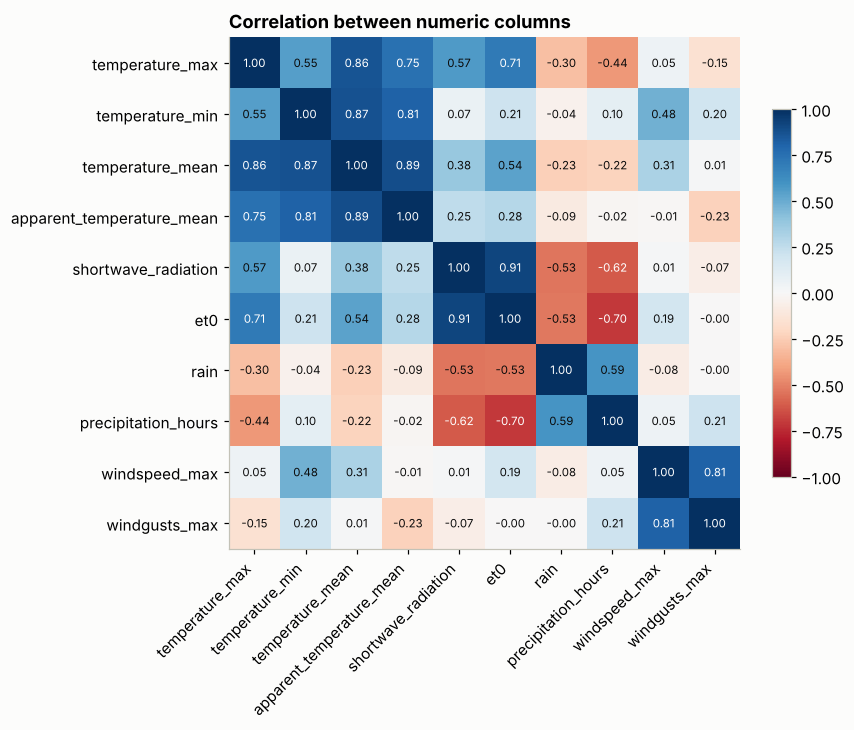

In [14]:
cols = ["temperature_2m_max", "temperature_2m_min", "temperature_2m_mean",
        "apparent_temperature_mean", "shortwave_radiation_sum", "et0_fao_evapotranspiration",
        "rain_sum", "precipitation_hours", "windspeed_10m_max", "windgusts_10m_max"]
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(corr.values, cmap="RdBu", vmin=-1, vmax=1)       # two colours with white at zero
short = [c.replace("_2m", "").replace("_10m", "").replace("_sum", "").replace("_fao_evapotranspiration", "") for c in cols]
ax.set_xticks(range(len(cols)), short, rotation=45, ha="right"); ax.set_yticks(range(len(cols)), short)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(corr.values[i, j]) > 0.6 else INK)
ax.grid(False); ax.set_title("Correlation between numeric columns")
fig.colorbar(im, ax=ax, shrink=0.7)
plt.show()

- `apparent_temperature_*` ("feels like") is calculated from temperature, humidity and wind, and is strongly correlated with temperature (0.89). A quick test showed it does not improve the prediction, so it is dropped to keep the input form short.
- `et0` (evaporation) and `shortwave_radiation` (sunshine) are strongly related to each other and negatively related to rain: sunny, dry days have high values.
- `weathercode` is a code that summarises today's rain amount, so it repeats `rain_sum` and `precipitation_hours`. It is dropped too.

## 8. A limitation of this dataset: shared rain grid cells

In [15]:
rain_table = df.pivot(index="time", columns="city", values="rain_sum")
groups = {}
for city in rain_table.columns:
    groups.setdefault(tuple(rain_table[city].round(2)), []).append(city)
print(f"Distinct rain series: {len(groups)} for {rain_table.shape[1]} cities\n")
for g in groups.values():
    if len(g) > 1:
        print("Same rain values every day:", ", ".join(g))

Distinct rain series: 15 for 30 cities

Same rain values every day: Athurugiriya, Gampaha, Kolonnawa, Mabole, Negombo, Oruwala, Sri Jayewardenepura Kotte
Same rain values every day: Bentota, Colombo, Kalutara, Kesbewa, Maharagama, Moratuwa, Mount Lavinia
Same rain values every day: Galle, Matara, Weligama
Same rain values every day: Kurunegala, Pothuhera


The data comes from a weather model (Open-Meteo reanalysis), not from rain gauges of the Department of Meteorology. The model stores rain on a coarse grid, so nearby cities share exactly the same rain series: only **15 different rain series** exist for the 30 cities. Temperature and wind are still different per city.

What this means for the project:
- The 30 cities are not 30 independent sources of information; the Colombo area is counted several times.
- The train/test split is by **time**, not by city, so this repetition cannot leak test answers into training.
- Very local rain (one town wet, the next one dry) cannot be learned from this data.

## 9. Summary and problem definition

**What the data shows**

1. Clean daily data: 30 cities, 13.5 years, no missing values, no duplicates.
2. Rain is frequent: 67% of days have at least 1 mm (the weather model tends to report light rain often).
3. Strong seasonality that depends on location: the south-west is wet from April to November, while the north and east are dry in the middle of the year and wettest from October to December.
4. Rain is persistent: 86% chance of rain after a rainy day, 28% after a dry day.
5. Rain amounts are heavily skewed, so a log transform is needed.
6. Only 15 distinct rain series for 30 cities (coarse grid).

**Prediction problem: classification**

> *Given today's weather and the rain of the last few days in a city, will it rain tomorrow (at least 1 mm)?*

- Target: `rain_tomorrow` = 1 if tomorrow's `rain_sum` is 1.0 mm or more, else 0. One millimetre is the standard "wet day" threshold in climate studies.
- Why classification: the lecturer's reference pipeline is a soft-voting **classifier**, and "rain or no rain" is the question people actually ask.
- Class balance: about 66% Rain and 34% No rain. This moderate imbalance is handled with class weights (`class_weight="balanced"` for Random Forest, `scale_pos_weight` for XGBoost).
- Split: by time. The earliest 80% of dates are used for training and the latest 20% for testing, because a forecast must always be tested on days that come after the training days.